# 12-апта · CNN · Ақылбек & Алмас

**Мақсат:** берілген notebook-тағы конволюция, padding, Sobel және pooling амалдарын
есептеп, CNN көмегімен MNIST пен Fashion-MNIST кескіндерін жіктеу.

**Ақылбек:** сүзгі, correlation/convolution айырмасы, padding, Sobel және pooling.
**Алмас:** модель архитектурасы, оқыту қисықтары, тест нәтижесі және қателер.

Colab-та қажетті пакеттерді жеке ұяшықта орнат:
%pip install tensorflow numpy scipy scikit-learn matplotlib scikit-image

Сақталған графиктер мен сандар нақты орындалған есептеулерден алынған.


In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "4")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import gzip
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras

OUT = Path(os.environ.get("CNN_OUT", "cnn-results"))
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
tf.keras.utils.set_random_seed(SEED)


def picture(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)
    try:
        get_ipython()
    except NameError:
        return
    from IPython.display import Image, display
    display(Image(filename=str(path)))

## 1 · Сүзгімен есептеу

CNN қабаты әдетте сүзгіні аудармайтын cross-correlation амалын орындайды.
Y[i,j] = Σ X[i+u,j+v] · K[u,v].
Математикалық convolution сүзгіні 180° аударады. Берілген 6×6 массив пен 3×3 сүзгі үшін
valid нәтижесі 4×4, бірінші correlation мәні −5. Stride — терезенің жылжу қадамы.
Шығыс өлшемі: floor((N + 2P − F) / S) + 1.


In [2]:
BIG = np.array([[3, 0, 1, 2, 7, 4], [1, 5, 8, 9, 3, 1],
                [2, 7, 2, 5, 1, 3], [0, 1, 3, 1, 7, 8],
                [4, 2, 1, 6, 2, 8], [2, 4, 5, 2, 3, 9]])
KERNEL = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])
correlation = signal.correlate2d(BIG, KERNEL, mode="valid")
convolution = signal.convolve2d(BIG, KERNEL, mode="valid")
print("Patch products at (0, 0):\n", BIG[:3, :3] * KERNEL)
print("Correlation:\n", correlation)
print("Convolution (flipped kernel):\n", convolution)
assert correlation[0, 0] == -5
assert np.array_equal(convolution, signal.correlate2d(BIG, KERNEL[::-1, ::-1], mode="valid"))
small_image = np.arange(9).reshape(3, 3)
small_kernel = np.array([[0, 1], [2, 3]])
print("Padding valid:\n", signal.correlate2d(small_image, small_kernel, mode="valid"))
print("Padding full:\n", signal.correlate2d(small_image, small_kernel, mode="full"))

Patch products at (0, 0):
 [[ 3  0 -1]
 [ 1  0 -8]
 [ 2  0 -2]]
Correlation:
 [[ -5  -4   0   8]
 [-10  -2   2   3]
 [  0  -2  -4  -7]
 [ -3  -2  -3 -16]]
Convolution (flipped kernel):
 [[ 5  4  0 -8]
 [10  2 -2 -3]
 [ 0  2  4  7]
 [ 3  2  3 16]]
Padding valid:
 [[19 25]
 [37 43]]
Padding full:
 [[ 0  3  8  4]
 [ 9 19 25 10]
 [21 37 43 16]
 [ 6  7  8  0]]


## 2 · Sobel, ReLU және MaxPooling

Sobel x бағыты бойынша жарықтықтың өзгерісін көрсетеді. Теріс мән де шекараның бағыты
туралы ақпарат береді. ReLU(z)=max(0,z) теріс мәнді нөлге айналдырады.
Pooling 2×2 терезеден ең үлкен мәнді таңдайды. 4×4 мысалдан [[4,8],[6,9]] аламыз.


Vertical-edge response:
 [[  0 540 540   0]
 [  0 540 540   0]
 [  0 540 540   0]
 [  0 540 540   0]]
Horizontal-edge response:
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
ReLU keeps positives:
 [[  0 540 540   0]
 [  0 540 540   0]
 [  0 540 540   0]
 [  0 540 540   0]]
2x2 max pooling:
 [[4 8]
 [6 9]]


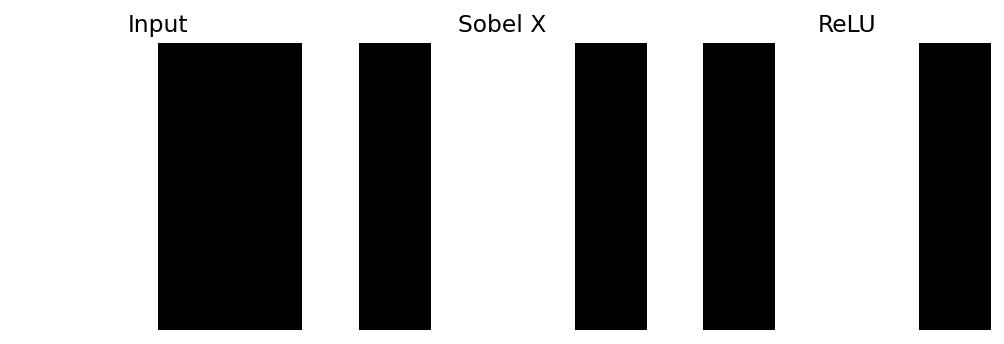

In [3]:
edge_image = np.tile([255, 255, 255, 120, 120, 120], (6, 1))
sobel_x = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])
sobel_y = sobel_x.T
gx = signal.correlate2d(edge_image, sobel_x, mode="valid")
gy = signal.correlate2d(edge_image, sobel_y, mode="valid")
print("Vertical-edge response:\n", gx)
print("Horizontal-edge response:\n", gy)
print("ReLU keeps positives:\n", np.maximum(0, gx))
pool_input = np.array([[1, 4, 2, 3], [3, 2, 8, 1], [0, 5, 7, 2], [6, 1, 4, 9]])
pool_output = pool_input.reshape(2, 2, 2, 2).max(axis=(1, 3))
print("2x2 max pooling:\n", pool_output)
from skimage import data, color, transform
photo_rgb = transform.resize(data.chelsea(), (64, 64), anti_aliasing=True)
photo_gray = color.rgb2gray(photo_rgb)
photo_gx = signal.correlate2d(photo_gray, sobel_x, mode="same", boundary="symm")
photo_gy = signal.correlate2d(photo_gray, sobel_y, mode="same", boundary="symm")
photo = dict(rgb=np.rint(photo_rgb*255).astype(int).tolist(),
             gray=np.rint(photo_gray*255).astype(int).tolist(),
             gx=photo_gx.round(5).tolist(), gy=photo_gy.round(5).tolist())
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, image, title in zip(axes, [edge_image, gx, np.maximum(0, gx)], ["Input", "Sobel X", "ReLU"]):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
picture(fig, "edges.png")

## 3 · Дерек және архитектура

MNIST: цифрлар. Fashion-MNIST: киімнің 10 түрі. Екеуінде 28×28 бір арналы кескіндер бар.
MNIST үшін x/255−0.5, Fashion-MNIST үшін x/255 қолданылады.
Оқыту/validation/test: 54 000 / 6 000 / 10 000.
Validation — модельді салыстыруға арналған бөлік; test оқытуға қатыспайды.
SparseCategoricalCrossentropy бүтін класс нөмірлерімен жұмыс істейді.


In [4]:
cache = os.environ.get("CNN_CACHE")
if cache:
    cache = Path(cache)
    with np.load(cache / "mnist.npz") as file:
        mnist = (file["x_train"], file["y_train"]), (file["x_test"], file["y_test"])
    def read_gz(name, offset):
        with gzip.open(cache / name, "rb") as file:
            return np.frombuffer(file.read(), dtype=np.uint8, offset=offset)
    fashion = (
        (read_gz("train-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28), read_gz("train-labels-idx1-ubyte.gz", 8)),
        (read_gz("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28), read_gz("t10k-labels-idx1-ubyte.gz", 8)),
    )
else:
    mnist = keras.datasets.mnist.load_data()
    fashion = keras.datasets.fashion_mnist.load_data()
print("TensorFlow:", tf.__version__)
print("MNIST / Fashion-MNIST:", mnist[0][0].shape, fashion[0][0].shape)


def dataset(x, y, shuffle=False, batch=128):
    data = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        data = data.shuffle(10000, seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return data.batch(batch).with_options(options).prefetch(1)


def architecture(kind):
    layers = keras.layers
    if kind == "base":
        model = keras.Sequential([
            layers.Input((28, 28, 1)), layers.Conv2D(8, 3, activation="relu", use_bias=False),
            layers.MaxPooling2D(2), layers.Flatten(), layers.Dense(10, activation="softmax", use_bias=False),
        ])
    elif kind == "improved":
        model = keras.Sequential([
            layers.Input((28, 28, 1)), layers.Conv2D(32, 3, activation="relu"),
            layers.MaxPooling2D(2), layers.Conv2D(64, 3, activation="relu"),
            layers.MaxPooling2D(2), layers.Flatten(), layers.Dropout(.5),
            layers.Dense(10, activation="softmax"),
        ])
    else:
        model = keras.Sequential([
            layers.Input((28, 28, 1)), layers.Conv2D(32, 3, activation="relu"),
            layers.MaxPooling2D(2), layers.Conv2D(64, 3, activation="relu"),
            layers.MaxPooling2D(2), layers.Conv2D(64, 3, activation="relu"),
            layers.Flatten(), layers.Dense(64, activation="relu"), layers.Dense(10, activation="softmax"),
        ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def train(name, kind, data, epochs, center=False, batch=128):
    keras.utils.set_random_seed(SEED)
    (x, y), (xt, yt) = data
    x = x.astype("float32")[..., None] / 255 - (.5 if center else 0)
    xt = xt.astype("float32")[..., None] / 255 - (.5 if center else 0)
    tr, val = train_test_split(np.arange(len(y)), test_size=.1, random_state=SEED, stratify=y)
    model = architecture(kind)
    snapshots = []
    probe = xt[:500]
    class Trace(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            snapshots.append(np.concatenate([model(probe[i:i+128], training=False).numpy() for i in range(0, len(probe), 128)]))
    snapshots.append(np.concatenate([model(probe[i:i+128], training=False).numpy() for i in range(0, len(probe), 128)]))
    history = model.fit(dataset(x[tr], y[tr], True, batch), validation_data=dataset(x[val], y[val]),
                        epochs=epochs, callbacks=[Trace()], verbose=2).history
    loss, accuracy = model.evaluate(dataset(xt, yt), verbose=0)
    probabilities = np.concatenate([model(v, training=False).numpy() for v, _ in dataset(xt, yt)])
    predictions = probabilities.argmax(axis=1)
    matrix = confusion_matrix(yt, predictions, labels=range(10))
    errors = np.flatnonzero(predictions[:500] != yt[:500])[:8]
    chosen = np.unique(np.r_[np.arange(10), errors])
    samples = []
    for i in chosen:
        samples.append({
            "index": int(i), "actual": int(yt[i]), "prediction": int(predictions[i]),
            "pixels": data[1][0][i].reshape(-1).tolist(),
            "probabilities": np.array([step[i] for step in snapshots]).round(6).tolist(),
        })
    extractor = keras.Model(model.inputs, [model.layers[0].output, model.layers[1].output])
    maps, pooled = extractor(xt[:1], training=False)
    top = sorted([(int(matrix[a, b]), a, b) for a in range(10) for b in range(10) if a != b], reverse=True)[:5]
    print(f"{name}: test={accuracy:.4%}, loss={loss:.4f}, parameters={model.count_params()}")
    print(classification_report(yt, predictions, zero_division=0, digits=3))
    result = dict(name=name, epochs=epochs, parameters=model.count_params(), accuracy=float(accuracy), loss=float(loss),
                  history=history, matrix=matrix.tolist(), train=54000, validation=6000, test=10000,
                  errors=int((predictions != yt).sum()), samples=samples,
                  filters=model.layers[0].get_weights()[0][:, :, 0, :8].transpose(2, 0, 1).round(5).tolist(),
                  maps=maps.numpy()[0, :, :, :8].transpose(2, 0, 1).round(4).tolist(),
                  pooled=pooled.numpy()[0, :, :, :8].transpose(2, 0, 1).round(4).tolist(),
                  top=[dict(actual=a, prediction=b, count=c) for c, a, b in top],
                  shapes=[dict(name=layer.name, shape=list(layer.output.shape)[1:]) for layer in model.layers])
    figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, key in zip(axes, ["accuracy", "loss"]):
        ax.plot(range(1, epochs+1), history[key], label="Train")
        ax.plot(range(1, epochs+1), history["val_"+key], label="Validation")
        ax.set(xlabel="Epoch", ylabel=key)
        ax.legend()
    picture(figure, kind + "-learning.png")
    figure, axes = plt.subplots(2, 5, figsize=(10, 4))
    wrong = np.flatnonzero(predictions != yt)[:10]
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(data[1][0][i], cmap="gray")
        ax.set_title(f"{yt[i]} → {predictions[i]}")
        ax.axis("off")
    picture(figure, kind + "-errors.png")
    (OUT / (kind + ".json")).write_text(json.dumps(result), encoding="utf-8")
    return result

TensorFlow: 2.21.0
MNIST / Fashion-MNIST: (60000, 28, 28) (60000, 28, 28)


## 4 · MNIST: екі CNN-ді салыстыру

Базалық: Conv2D(8,3,valid,ReLU,bias=False) → MaxPool(2) → Flatten → Dense(10,Softmax,bias=False).
Өлшемдер: 28 → 26 → 13 → 1352 → 10.
Жақсартылған: Conv32 → Pool → Conv64 → Pool → Flatten → Dropout(0.5) → Dense10.
Екінші модель ұзақтау оқытылады, сондықтан дәлдік айырмасы тек архитектура әсері емес.


Epoch 1/3
422/422 - 2s - 5ms/step - accuracy: 0.8479 - loss: 0.5986 - val_accuracy: 0.9168 - val_loss: 0.2836
Epoch 2/3
422/422 - 2s - 4ms/step - accuracy: 0.9390 - loss: 0.2132 - val_accuracy: 0.9480 - val_loss: 0.1890
Epoch 3/3
422/422 - 2s - 4ms/step - accuracy: 0.9561 - loss: 0.1522 - val_accuracy: 0.9618 - val_loss: 0.1437
MNIST · CNN 8: test=96.3900%, loss=0.1307, parameters=13592
              precision    recall  f1-score   support

           0      0.964     0.989     0.976       980
           1      0.983     0.992     0.988      1135
           2      0.946     0.955     0.951      1032
           3      0.961     0.959     0.960      1010
           4      0.969     0.975     0.972       982
           5      0.970     0.957     0.964       892
           6      0.962     0.979     0.971       958
           7      0.959     0.951     0.955      1028
           8      0.965     0.938     0.952       974
           9      0.958     0.940     0.948      1009

    accuracy  

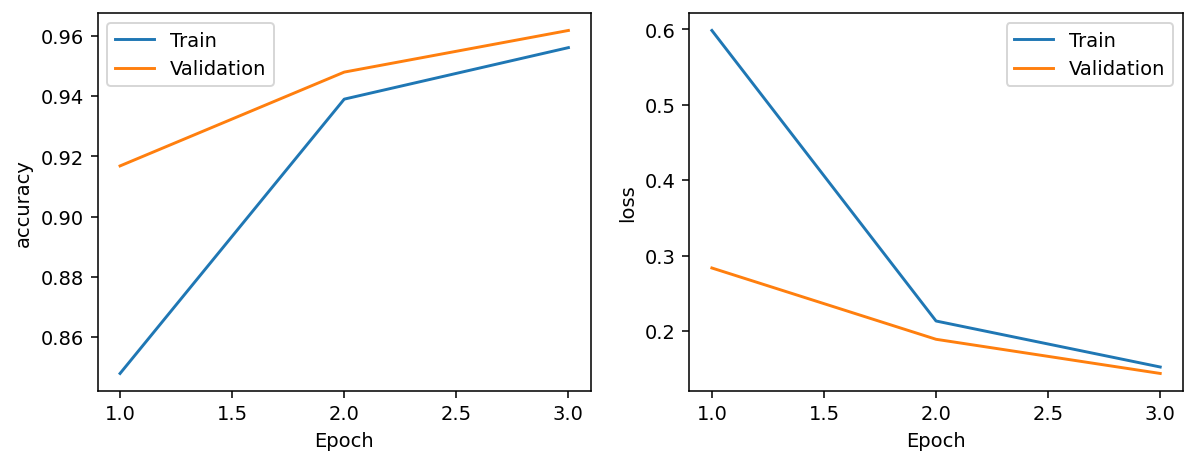

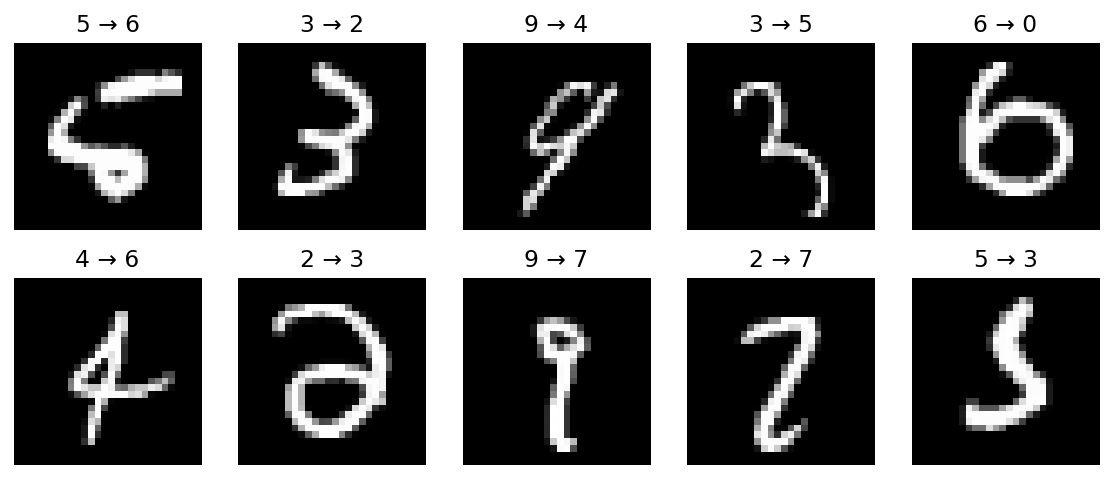

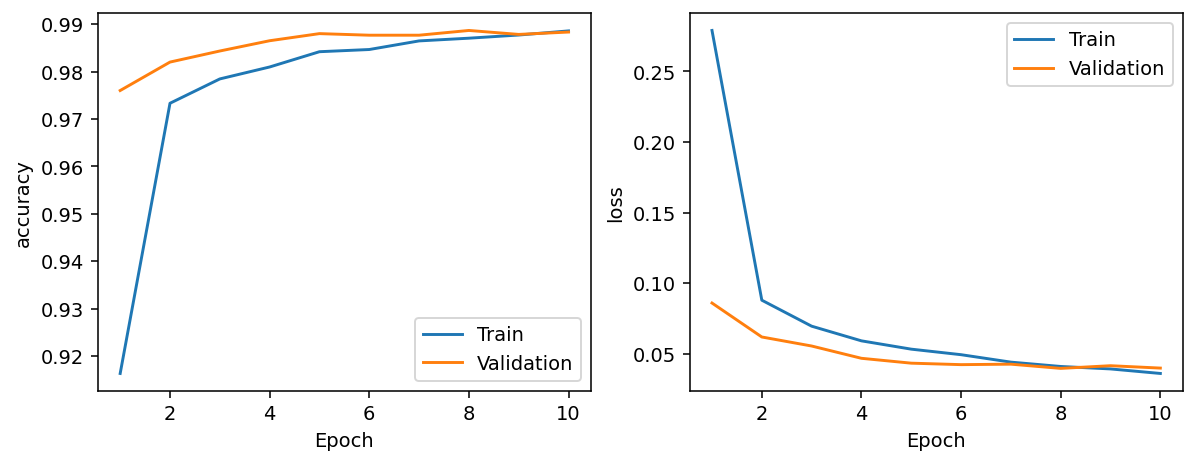

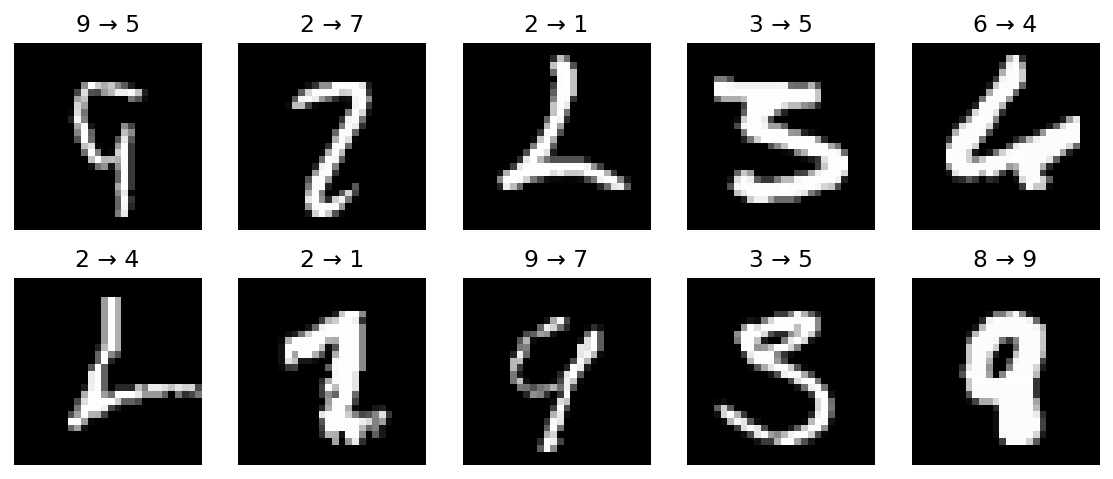

In [5]:
base = train("MNIST · CNN 8", "base", mnist, 3, center=True)
improved = train("MNIST · CNN 32/64", "improved", mnist, 10, center=True, batch=64)

## 5 · Fashion-MNIST: киімдерді тану

Conv32 → Pool → Conv64 → Pool → Conv64 → Flatten → Dense64 → Dense10.
Valid padding кезінде өлшемдер: 28 → 26 → 13 → 11 → 5 → 3.
Оқыту 5 эпоха, batch_size=64. Қателер матрицасында жол — нақты киім, баған — болжам.


Epoch 1/5
844/844 - 11s - 13ms/step - accuracy: 0.8028 - loss: 0.5512 - val_accuracy: 0.8645 - val_loss: 0.3769
Epoch 2/5
844/844 - 10s - 11ms/step - accuracy: 0.8759 - loss: 0.3439 - val_accuracy: 0.8917 - val_loss: 0.3033
Epoch 3/5
844/844 - 10s - 11ms/step - accuracy: 0.8910 - loss: 0.2975 - val_accuracy: 0.9003 - val_loss: 0.2774
Epoch 4/5
844/844 - 10s - 12ms/step - accuracy: 0.9014 - loss: 0.2677 - val_accuracy: 0.9075 - val_loss: 0.2573
Epoch 5/5
844/844 - 10s - 11ms/step - accuracy: 0.9104 - loss: 0.2454 - val_accuracy: 0.8948 - val_loss: 0.2916
Fashion-MNIST · CNN: test=88.7500%, loss=0.3202, parameters=93322
              precision    recall  f1-score   support

           0      0.740     0.924     0.822      1000
           1      0.985     0.979     0.982      1000
           2      0.757     0.924     0.832      1000
           3      0.913     0.876     0.894      1000
           4      0.860     0.794     0.826      1000
           5      0.985     0.969     0.977      

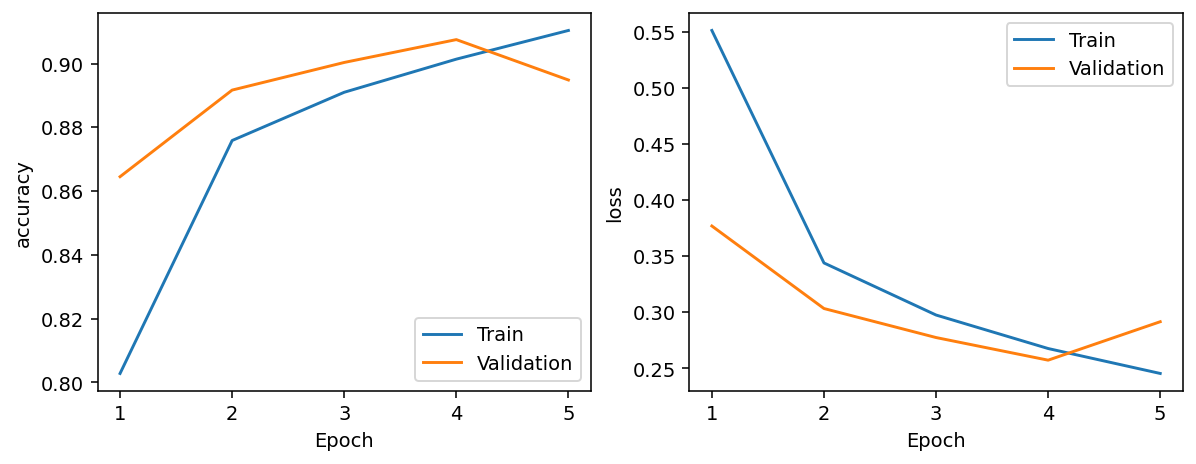

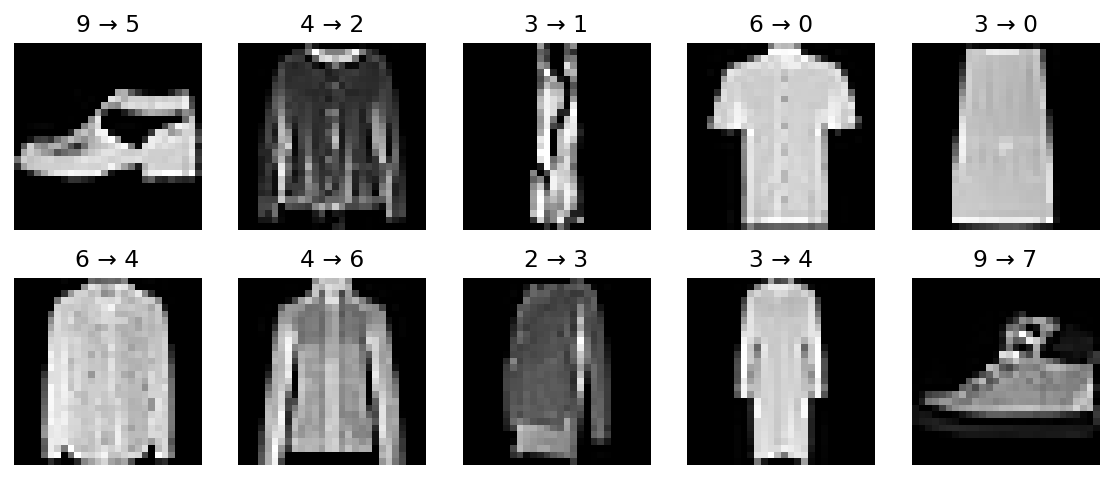

In [6]:
fashion_result = train("Fashion-MNIST · CNN", "fashion", fashion, 5, batch=64)

## 6 · Нәтижелерді сақтау

JSON ішінде оқыту тарихы, тест матрицасы, таңдалған кескіндердің әр эпохадағы ықтималдықтары,
бірінші Conv2D сүзгілері мен feature map карталары сақталады. Сайт анимациясы сол жазбаларды көрсетеді.


In [7]:
results = dict(models=[base, improved, fashion_result], tensorflow=tf.__version__,
               correlation=correlation.tolist(), convolution=convolution.tolist(),
               edge=gx.tolist(), pooling=pool_output.tolist(), photo=photo)
(OUT / "cnn-results.json").write_text(json.dumps(results), encoding="utf-8")
print("Saved:", OUT / "cnn-results.json")

Saved: C:\Users\User\Documents\Codex\2026-11-11\https-kuatakylbek44-ai-github-io-svm\work\cnn-run\cnn-results.json


## 7 · Colab-тағы RGB бөлімі: CIFAR-10

Бұл бөлім берілген notebook-тағы 32×32×3 кескін архитектурасын қайталайды.
RGB арнасының үшеуі де сүзгіге қатысады. BatchNormalization белсендіру мәндерінің
масштабын реттейді. Бұл модель осы жұмыста оқытылған жоқ, сондықтан тест дәлдігі берілмейді.
Толық файлды --cifar параметрімен орындағанда жеке оқытылады.


In [ ]:
if "--cifar" in sys.argv:
    # CIFAR-10 architecture from the provided Colab. No measured score is claimed in the lab.
    (x, y), (xt, yt) = keras.datasets.cifar10.load_data()
    x, xt = x.astype("float32")/255-.5, xt.astype("float32")/255-.5
    y, yt = y.ravel(), yt.ravel()
    tr, val = train_test_split(np.arange(len(y)), test_size=.1, random_state=SEED, stratify=y)
    layers = keras.layers
    rgb = keras.Sequential([
        layers.Input((32,32,3)), layers.Conv2D(64,5,activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(2), layers.Conv2D(128,3,activation="relu"), layers.BatchNormalization(),
        layers.Conv2D(256,3,activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Flatten(), layers.Dropout(.5), layers.Dense(1024,activation="relu"),
        layers.Dropout(.5), layers.Dense(1024,activation="relu"), layers.Dropout(.5),
        layers.Dense(512,activation="relu"), layers.Dense(10,activation="softmax"),
    ])
    rgb.compile(optimizer=keras.optimizers.Adam(.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    rgb.fit(dataset(x[tr],y[tr],True,64),validation_data=dataset(x[val],y[val]),epochs=10,verbose=2)
    print("CIFAR-10 test:",rgb.evaluate(dataset(xt,yt),verbose=0))

## Қорытынды

|Модель|Эпоха|Параметр|Test accuracy|Қате саны|
|---|---:|---:|---:|---:|
|MNIST · CNN 8|3|13,592|96.39%|361|
|MNIST · CNN 32/64|10|34,826|99.07%|93|
|Fashion-MNIST · CNN|5|93,322|88.75%|1125|

Ақылбек: «Сүзгі әр терезедегі пиксельдерді салмақтарына көбейтіп қосады.
ReLU теріс мәнді жояды, pooling картаны кішірейтеді».

Алмас: «Оқытуда сүзгі салмақтары автоматты үйреніледі. Сайтта бір кескінді таңдап,
эпохалар бойынша ықтималдықтың өзгерісін көрсетеміз. Бір кескіннің ықтималдығы
жалпы тест дәлдігіне тең емес».

CNN8 3 эпоха, CNN32/64 10 эпоха оқытылды. Екеуі бірдей train/validation/test бөлінісін қолданды.
CIFAR-10 бөлімі — қосымша орындалатын код; оған өлшенбеген нәтиже жазылған жоқ.
